# Yield Curve Recession Model: Can the Bond Market Predict US Recessions?

**Research question:** how well does the slope of the yield curve predict US recessions twelve months ahead, how does it compare with a real-time labour-market signal (the Sahm rule), and what do these indicators say today?

An **inverted yield curve**, when short-term interest rates are above long-term ones, has preceded every US recession since the late 1960s. It is the most famous recession indicator in finance, and the New York Fed publishes a monthly recession probability based on it.

The notebook is organised in seven steps:

1. **Data**: Treasury yields, credit spreads, unemployment and official recession dates
2. **The yield curve and recessions**: a first look at the data
3. **Probit model**: recession probability 12 months ahead, estimated on the full sample
4. **Out-of-sample test**: would the model have worked in real time?
5. **Lead times and false alarms**: inversion by inversion, recession by recession
6. **The Sahm rule**: a labour-market signal that confirms recessions once they start
7. **Today's reading and automatic export** for GitHub

**How to use it:** check the settings in the first code cell, then *Runtime → Run all*. At the end a zip file with README, charts and tables is downloaded automatically.

> Research and educational project. Not investment advice.

In [1]:
# ============================================================================
# SETTINGS: change these before running
# ============================================================================
AUTHOR = "Mattia Mariani"
GITHUB_USERNAME = "gabsmm18"
REPO_NAME = "yield-curve-recession-model"
NOTEBOOK_NAME = "yield_curve_recession_model.ipynb"

In [2]:
import os
import shutil
import warnings
from datetime import date

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from sklearn.metrics import roc_auc_score, roc_curve

warnings.filterwarnings("ignore")
pd.set_option("display.float_format", "{:.2f}".format)
plt.rcParams.update({"figure.figsize": (12, 5), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

# --- Model parameters -------------------------------------------------------
HORIZON = 12                    # months ahead
ESTIMATION_START = "1959-01-01"
OOS_START = "1978-01-01"        # first out-of-sample forecast
SAHM_THRESHOLD = 0.5
MODELS = {"Spread only": ["spread"], "Spread + credit": ["spread", "credit_spread"]}
MODEL_COLORS = {"Spread only": "#1f4e79", "Spread + credit": "#c62828"}

# --- Output folders (everything inside OUT is what goes on GitHub) ----------
OUT = "github_export"
FIG = f"{OUT}/figures"
TAB = f"{OUT}/tables"
for d in (FIG, TAB):
    os.makedirs(d, exist_ok=True)


def save(fig, name):
    fig.savefig(f"{FIG}/{name}", dpi=150, bbox_inches="tight")


def shade_recessions(ax, rec, start=None):
    # Grey bands for NBER recessions
    r = rec.loc[start:] if start else rec
    in_rec, s = False, None
    for d, v in r.items():
        if v == 1 and not in_rec:
            in_rec, s = True, d
        elif v != 1 and in_rec:
            ax.axvspan(s, d, color="grey", alpha=0.25, lw=0)
            in_rec = False
    if in_rec:
        ax.axvspan(s, r.index[-1], color="grey", alpha=0.25, lw=0)

## Step 1: Data

All series are monthly averages from **FRED** (Federal Reserve Bank of St. Louis). No API key is needed.

| Series | FRED code | Role |
|---|---|---|
| 10-year Treasury yield | GS10 | Long end of the curve |
| 3-month Treasury bill | TB3MS | Short end of the curve |
| 2-year Treasury yield | GS2 | Alternative short end (from 1976) |
| Moody's BAA corporate yield | BAA | Credit risk (BAA minus 10-year) |
| Unemployment rate | UNRATE | Sahm rule |
| NBER recession indicator | USREC | Official recession dates (1 = recession) |

**Which spread?** The main indicator is the **10-year minus 3-month** spread, the one used by the New York Fed: research by Estrella and Mishkin found it to be the most reliable predictor. The 10-year minus 2-year spread, more popular in the financial press, is shown for comparison.

**Why does the curve predict recessions?** Two reasons. First, **expectations**: long-term yields reflect the expected path of short-term rates, so if markets expect the central bank to cut rates in a coming downturn, long yields fall below short ones. Second, **monetary policy**: an inversion usually means the central bank has raised short rates to a restrictive level, which squeezes bank lending margins (banks borrow short and lend long) and slows the economy.

Isolated missing months (for example the October 2025 data not published during the US government shutdown) are filled by linear interpolation.

In [3]:
def fred(series_id):
    url = f"https://fred.stlouisfed.org/graph/fredgraph.csv?id={series_id}"
    df = pd.read_csv(url, index_col=0, parse_dates=True, na_values=".")
    return df.iloc[:, 0].astype(float).dropna()


raw = {code: fred(code).resample("MS").mean() for code in ["GS10", "TB3MS", "GS2", "BAA", "UNRATE", "USREC"]}
df = pd.DataFrame(raw).loc["1953-04-01":]
cont = ["GS10", "TB3MS", "GS2", "BAA", "UNRATE"]
df[cont] = df[cont].interpolate(limit=2, limit_area="inside")

df["spread"] = df["GS10"] - df["TB3MS"]               # 10y - 3m
df["spread_2y"] = df["GS10"] - df["GS2"]              # 10y - 2y
df["credit_spread"] = df["BAA"] - df["GS10"]          # BAA - 10y

# Sahm rule: 3-month average unemployment minus its lowest 3-month average of the previous 12 months
u3 = df["UNRATE"].rolling(3).mean()
df["sahm"] = u3 - u3.shift(1).rolling(12).min()

# Target: is the economy in recession 12 months from now? (same definition as the New York Fed)
df["target"] = df["USREC"].shift(-HORIZON)

LAST = df["spread"].last_valid_index()
LAST_REC_KNOWN = df["USREC"].last_valid_index()
print(f"Data: {df.index[0]:%b %Y} -> {LAST:%b %Y}; NBER indicator available to {LAST_REC_KNOWN:%b %Y}")
df[["GS10", "TB3MS", "spread", "spread_2y", "credit_spread", "UNRATE", "sahm", "USREC"]].tail()

Data: Apr 1953 -> Oct 2026; NBER indicator available to Oct 2026


,GS10,TB3MS,spread,spread_2y,credit_spread,UNRATE,sahm,USREC
observation_date,,,,,,,,
2026-06-01,4.47,3.66,0.81,0.36,1.53,4.20,0.07,0.00
2026-07-01,4.60,3.73,0.87,0.38,1.59,4.10,-0.03,0.00
2026-08-01,4.68,3.72,0.96,0.46,1.64,4.10,-0.07,0.00
2026-09-01,4.99,3.94,1.05,0.34,1.48,4.20,0.00,0.00
2026-10-01,5.13,4.05,1.08,0.39,1.46,4.10,0.00,0.00


## Step 2: The yield curve and recessions

Grey bands are NBER recessions. Look at what happens to the spread in the year or two before each band.

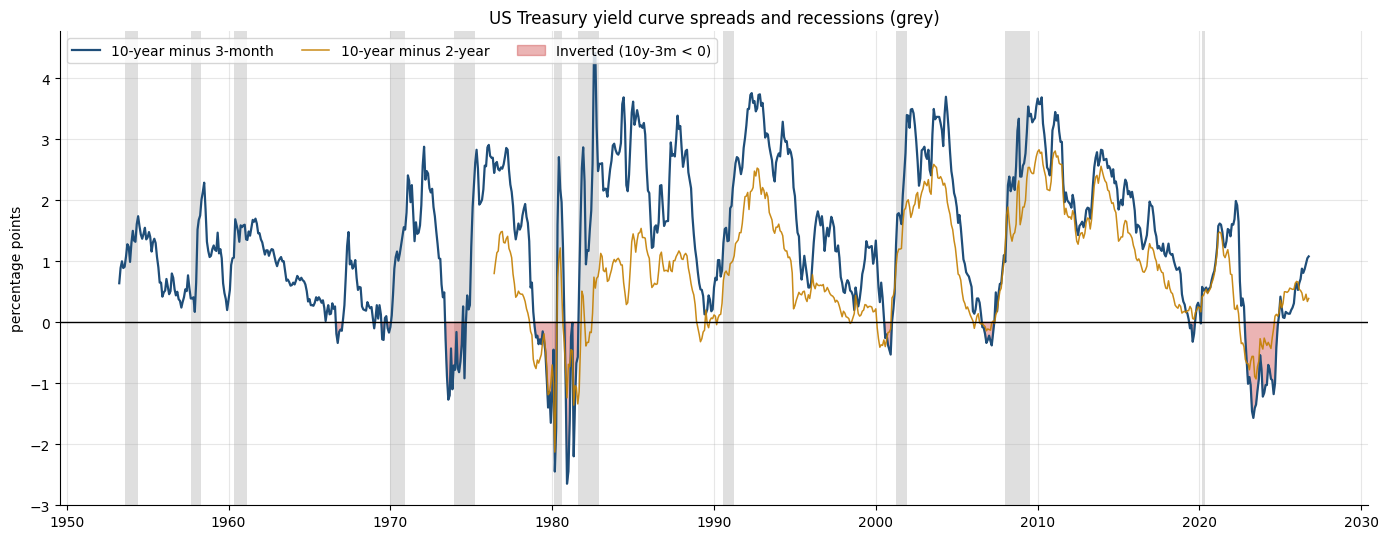

In [4]:
fig, ax = plt.subplots(figsize=(14, 5.5))
shade_recessions(ax, df["USREC"])
ax.plot(df.index, df["spread"], color="#1f4e79", lw=1.6, label="10-year minus 3-month")
ax.plot(df.index, df["spread_2y"], color="#c47f00", lw=1.1, alpha=0.9, label="10-year minus 2-year")
ax.axhline(0, color="black", lw=1)
ax.fill_between(df.index, df["spread"], 0, where=df["spread"] < 0, color="#c62828", alpha=0.35,
                label="Inverted (10y-3m < 0)")
ax.set_ylabel("percentage points")
ax.set_title("US Treasury yield curve spreads and recessions (grey)")
ax.legend(loc="upper left", ncol=3)
fig.tight_layout()
save(fig, "01_yield_curve_spreads.png")
plt.show()

## Step 3: Probit model

A **probit** model estimates the probability of a yes/no event, here *"will the US be in recession in 12 months?"*, as a function of explanatory variables:

$$P(\text{recession}_{t+12} = 1) = \Phi(\alpha + \beta\, \text{spread}_t)$$

where $\Phi$ is the cumulative standard normal distribution, which maps any number into a probability between 0 and 1. This is the model of Estrella and Mishkin (1998) and of the New York Fed. A negative $\beta$ means that a flatter or inverted curve raises the probability of recession.

Two versions are estimated:
- **Spread only**: the classic model;
- **Spread + credit**: adds the BAA corporate spread, which captures stress in credit markets. Wider credit spreads mean lenders demand more compensation for default risk, a typical pre-recession signal.

Standard errors are robust to autocorrelation (HAC), since overlapping 12-month horizons make errors strongly autocorrelated. Fit is measured by McFadden's pseudo-R² and by the **AUC** (area under the ROC curve): 0.5 means no predictive power, 1 means perfect separation of recession and non-recession months.

In [5]:
def fit_probit(cols, data):
    d = data.dropna(subset=cols + ["target"])
    return sm.Probit(d["target"], sm.add_constant(d[cols])).fit(
        disp=0, cov_type="HAC", cov_kwds={"maxlags": HORIZON})


def predict(model, cols, data):
    X = sm.add_constant(data[cols].dropna(), has_constant="add")
    return pd.Series(model.predict(X), index=X.index)


sample = df.loc[ESTIMATION_START:]
fits, insample = {}, {}
rows = {}
for name, cols in MODELS.items():
    m = fit_probit(cols, sample)
    fits[name] = m
    insample[name] = predict(m, cols, sample)
    known = sample.dropna(subset=cols + ["target"])
    row = {"months": int(m.nobs), "pseudo R²": m.prsquared,
           "AUC (in-sample)": roc_auc_score(known["target"], insample[name].loc[known.index])}
    for c in ["const"] + cols:
        row[f"{c}"] = m.params[c]
        row[f"{c} s.e."] = m.bse[c]
    rows[name] = row
probit_table = pd.DataFrame(rows).T
probit_table.to_csv(f"{TAB}/probit_estimates.csv")
display(probit_table)

# Spread at which the probability crosses key thresholds (spread-only model)
a, b = fits["Spread only"].params["const"], fits["Spread only"].params["spread"]
from scipy.stats import norm
thresholds = {p: (norm.ppf(p) - a) / b for p in [0.2, 0.3, 0.5]}
for p, s in thresholds.items():
    print(f"Probability of {p:.0%} when the 10y-3m spread is {s:+.2f} pp")

,months,pseudo R²,AUC (in-sample),const,const s.e.,spread,spread s.e.,credit_spread,credit_spread s.e.
Spread only,802.00,0.19,0.82,-0.67,0.20,-0.56,0.12,NaN,NaN
Spread + credit,802.00,0.19,0.82,-0.68,0.43,-0.56,0.13,0.01,0.24


Probability of 20% when the 10y-3m spread is +0.30 pp
Probability of 30% when the 10y-3m spread is -0.27 pp
Probability of 50% when the 10y-3m spread is -1.20 pp


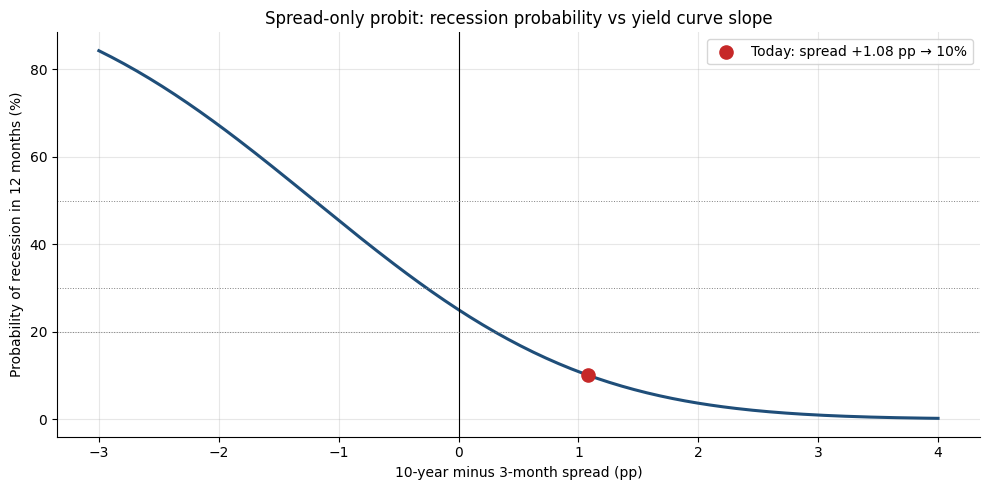

In [6]:
# Probability as a function of the spread
grid = np.linspace(-3, 4, 200)
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(grid, norm.cdf(a + b * grid) * 100, color=MODEL_COLORS["Spread only"], lw=2.2)
now_spread = df.loc[LAST, "spread"]
now_p = norm.cdf(a + b * now_spread) * 100
ax.scatter([now_spread], [now_p], s=90, color="#c62828", zorder=5, label=f"Today: spread {now_spread:+.2f} pp → {now_p:.0f}%")
ax.axvline(0, color="black", lw=0.8)
for p, s in thresholds.items():
    ax.axhline(p * 100, color="grey", lw=0.7, ls=":")
ax.set_xlabel("10-year minus 3-month spread (pp)")
ax.set_ylabel("Probability of recession in 12 months (%)")
ax.set_title("Spread-only probit: recession probability vs yield curve slope")
ax.legend()
fig.tight_layout()
save(fig, "02_probability_vs_spread.png")
plt.show()

## Step 4: Out-of-sample test

The full-sample model "knows" all the recessions it is fitted on. The honest question is: **would it have worked in real time?**

From 1978 onwards, every month the model is re-estimated using **only the data that would have been available**: since the target is a recession 12 months ahead, at month $t$ the model can only learn from outcomes up to $t$, i.e. from predictors up to $t-12$. It then forecasts the probability of a recession 12 months later. This is an **expanding-window** test, similar to the walk-forward approach in machine learning.

In [7]:
oos = {name: pd.Series(np.nan, index=df.index) for name in MODELS}
forecast_dates = df.loc[OOS_START:LAST].index
for t in forecast_dates:
    train = df.loc[ESTIMATION_START:t - pd.DateOffset(months=HORIZON)]
    for name, cols in MODELS.items():
        d = train.dropna(subset=cols + ["target"])
        x_t = df.loc[[t], cols]
        if x_t.isna().any(axis=None):
            continue
        m = sm.Probit(d["target"], sm.add_constant(d[cols])).fit(disp=0)
        oos[name].loc[t] = float(np.asarray(m.predict(sm.add_constant(x_t, has_constant="add")))[0])

eval_rows = {}
eval_set = df.loc[OOS_START:].dropna(subset=["target"])
for name in MODELS:
    p = oos[name].loc[eval_set.index].dropna()
    y = eval_set.loc[p.index, "target"]
    eval_rows[name] = {"months": len(p), "AUC out-of-sample": roc_auc_score(y, p),
                       "AUC in-sample, same months": roc_auc_score(y, insample[name].loc[p.index]),
                       "avg probability, recession months (%)": 100 * p[y == 1].mean(),
                       "avg probability, other months (%)": 100 * p[y == 0].mean()}
oos_table = pd.DataFrame(eval_rows).T
oos_table.to_csv(f"{TAB}/out_of_sample_evaluation.csv")
display(oos_table)

,months,AUC out-of-sample,"AUC in-sample, same months","avg probability, recession months (%)","avg probability, other months (%)"
Spread only,574.00,0.80,0.82,31.13,11.63
Spread + credit,574.00,0.78,0.82,29.94,12.40


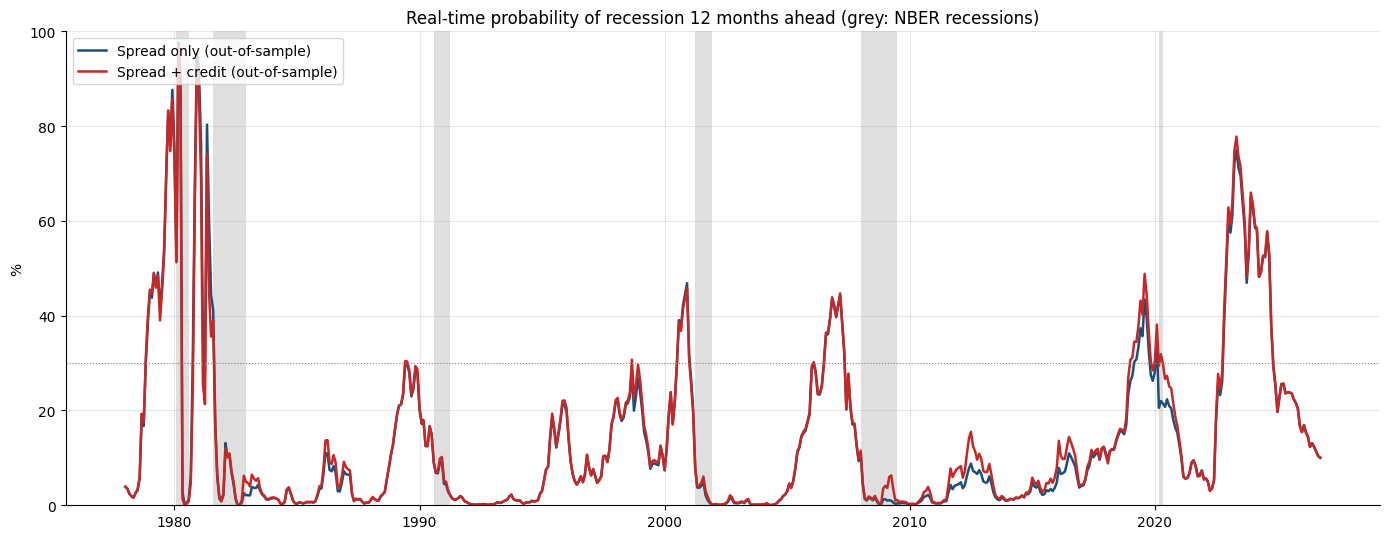

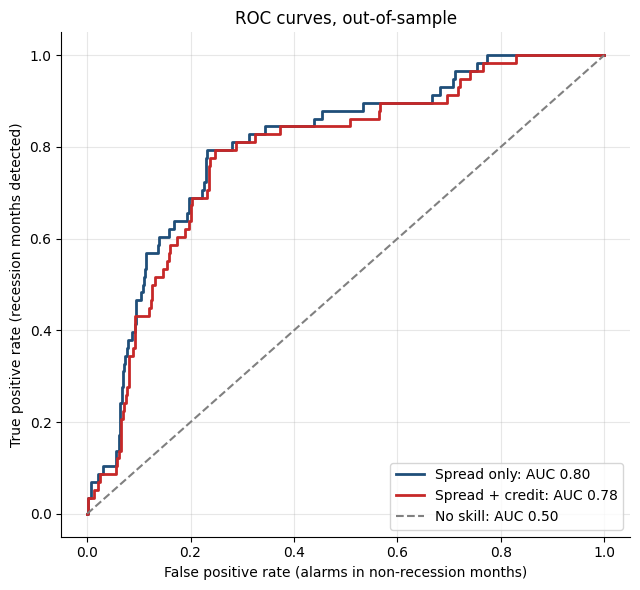

In [8]:
fig, ax = plt.subplots(figsize=(14, 5.5))
shade_recessions(ax, df["USREC"], OOS_START)
for name in MODELS:
    s = (oos[name] * 100).loc[OOS_START:]
    ax.plot(s.index, s, color=MODEL_COLORS[name], lw=1.8, label=f"{name} (out-of-sample)")
ax.axhline(30, color="grey", lw=0.8, ls=":")
ax.set_ylabel("%")
ax.set_ylim(0, 100)
ax.set_title("Real-time probability of recession 12 months ahead (grey: NBER recessions)")
ax.legend(loc="upper left")
fig.tight_layout()
save(fig, "03_recession_probability.png")
plt.show()

fig, ax = plt.subplots(figsize=(6.5, 6))
for name in MODELS:
    p = oos[name].loc[eval_set.index].dropna()
    y = eval_set.loc[p.index, "target"]
    fpr, tpr, _ = roc_curve(y, p)
    ax.plot(fpr, tpr, color=MODEL_COLORS[name], lw=2, label=f"{name}: AUC {roc_auc_score(y, p):.2f}")
ax.plot([0, 1], [0, 1], color="grey", ls="--", label="No skill: AUC 0.50")
ax.set_xlabel("False positive rate (alarms in non-recession months)")
ax.set_ylabel("True positive rate (recession months detected)")
ax.set_title("ROC curves, out-of-sample")
ax.legend(loc="lower right")
fig.tight_layout()
save(fig, "04_roc_curves.png")
plt.show()

## Step 5: Lead times and false alarms

Two tables, both built automatically from the data:

1. **Recession by recession:** how many months before each recession the curve first inverted, the highest real-time probability in the year before it started, and when the Sahm rule was triggered.
2. **Inversion by inversion:** every episode in which the 10y-3m spread was negative, and whether a recession followed within 24 months. An inversion with no recession is a **false alarm**.

In [9]:
def months_between(a, b):
    return (b.year - a.year) * 12 + (b.month - a.month)


rec = df["USREC"].dropna()
all_starts = rec.index[(rec == 1) & (rec.shift(1) == 0)]
starts = all_starts[all_starts >= pd.Timestamp("1960-01-01")]

recession_rows = {}
for s in starts:
    window = df.loc[s - pd.DateOffset(months=24):s - pd.DateOffset(months=1), "spread"]
    inv = window[window < 0]
    pre = oos["Spread only"].loc[s - pd.DateOffset(months=12):s - pd.DateOffset(months=1)].dropna()
    sahm_w = df.loc[s - pd.DateOffset(months=3):s + pd.DateOffset(months=18), "sahm"]
    trig = sahm_w[sahm_w >= SAHM_THRESHOLD]
    recession_rows[f"{s:%b %Y}"] = {
        "first inversion": f"{inv.index[0]:%b %Y}" if len(inv) else "no inversion",
        "lead (months)": months_between(inv.index[0], s) if len(inv) else np.nan,
        "max real-time probability (%)": 100 * pre.max() if len(pre) else np.nan,
        "Sahm rule triggered": f"{trig.index[0]:%b %Y}" if len(trig) else "not triggered",
        "Sahm lag (months)": months_between(s, trig.index[0]) if len(trig) else np.nan,
    }
recession_table = pd.DataFrame(recession_rows).T
recession_table.index.name = "Recession start"
recession_table.to_csv(f"{TAB}/recessions_lead_times.csv")
display(recession_table)

# Inversion episodes (months with spread < 0, merging gaps of up to 3 months)
neg = df.loc[ESTIMATION_START:LAST, "spread"] < 0
episodes, cur = [], None
for d, v in neg.items():
    if v:
        if cur and months_between(cur[1], d) <= 4:
            cur[1] = d
        else:
            if cur:
                episodes.append(cur)
            cur = [d, d]
if cur:
    episodes.append(cur)

episode_rows = {}
for a_, b_ in episodes:
    n_months = int(neg.loc[a_:b_].sum())
    if n_months < 2:
        continue
    follow = [s for s in all_starts if 0 <= months_between(a_, s) <= 24]
    if follow:
        status = f"recession ({follow[0]:%b %Y}, {months_between(a_, follow[0])} months later)"
    elif months_between(a_, LAST_REC_KNOWN) < 24:
        status = "too early to tell"
    else:
        status = "no recession within 24 months (false alarm)"
    episode_rows[f"{a_:%b %Y} - {b_:%b %Y}"] = {
        "inverted months": n_months,
        "deepest inversion (pp)": df.loc[a_:b_, "spread"].min(),
        "outcome": status,
    }
episode_table = pd.DataFrame(episode_rows).T
episode_table.index.name = "Inversion episode"
episode_table.to_csv(f"{TAB}/inversion_episodes.csv")
display(episode_table)

,first inversion,lead (months),max real-time probability (%),Sahm rule triggered,Sahm lag (months)
Recession start,,,,,
May 1960,no inversion,NaN,NaN,Oct 1960,5
Jan 1970,Jan 1969,12,NaN,Mar 1970,2
Dec 1973,Jun 1973,6,NaN,Jul 1974,7
Feb 1980,Dec 1978,14,87.65,Feb 1980,0
Aug 1981,Aug 1979,24,95.16,Nov 1981,3
Aug 1990,no inversion,NaN,28.60,Oct 1990,2
Apr 2001,Aug 2000,8,46.86,Jun 2001,2
Jan 2008,Aug 2006,17,44.26,Feb 2008,1
Mar 2020,Jun 2019,9,43.41,Apr 2020,1


,inverted months,deepest inversion (pp),outcome
Inversion episode,,,
Sep 1966 - Jan 1967,5,-0.34,no recession within 24 months (false alarm)
Jul 1969 - Jan 1970,5,-0.29,"recession (Jan 1970, 6 months later)"
Jun 1973 - Sep 1974,15,-1.27,"recession (Dec 1973, 6 months later)"
Dec 1978 - Apr 1980,17,-2.45,"recession (Feb 1980, 14 months later)"
Nov 1980 - Aug 1981,10,-2.65,"recession (Aug 1981, 9 months later)"
Aug 2000 - Dec 2000,5,-0.53,"recession (Apr 2001, 8 months later)"
Aug 2006 - Apr 2007,9,-0.38,"recession (Jan 2008, 17 months later)"
Jun 2019 - Sep 2019,4,-0.32,"recession (Mar 2020, 9 months later)"
Nov 2022 - Nov 2024,25,-1.57,no recession within 24 months (false alarm)


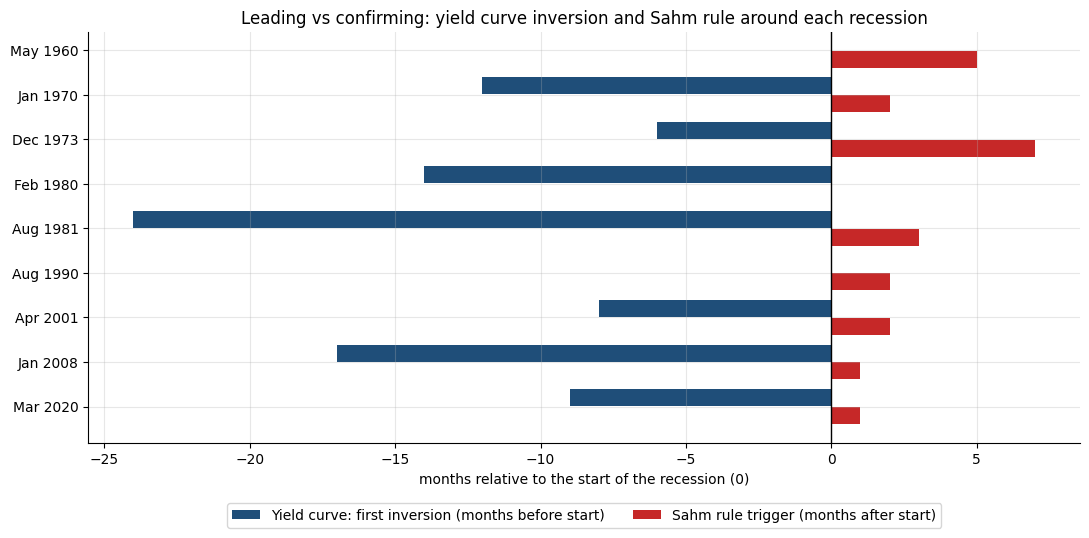

In [10]:
fig, ax = plt.subplots(figsize=(11, 5.5))
rt = recession_table.copy()
y = np.arange(len(rt))
ax.barh(y - 0.2, -rt["lead (months)"].astype(float), height=0.38, color="#1f4e79",
        label="Yield curve: first inversion (months before start)")
ax.barh(y + 0.2, rt["Sahm lag (months)"].astype(float), height=0.38, color="#c62828",
        label="Sahm rule trigger (months after start)")
ax.axvline(0, color="black", lw=1)
ax.set_yticks(y, rt.index)
ax.invert_yaxis()
ax.set_xlabel("months relative to the start of the recession (0)")
ax.set_title("Leading vs confirming: yield curve inversion and Sahm rule around each recession")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.13), ncol=2)
fig.tight_layout()
save(fig, "05_lead_times.png")
plt.show()

## Step 6: The Sahm rule

Developed by economist Claudia Sahm, the rule signals that a recession has **started** when the three-month average unemployment rate rises at least **0.5 points** above its lowest level of the previous twelve months.

It is a different kind of signal from the yield curve:
- the yield curve is a **leading** indicator: it warns 6-24 months in advance, but the timing is uncertain and there are false alarms;
- the Sahm rule is a **confirming** indicator: it fires only once a recession is under way, but historically with very few false signals.

A strategist uses both: the curve to raise the alarm, the labour market to confirm it.

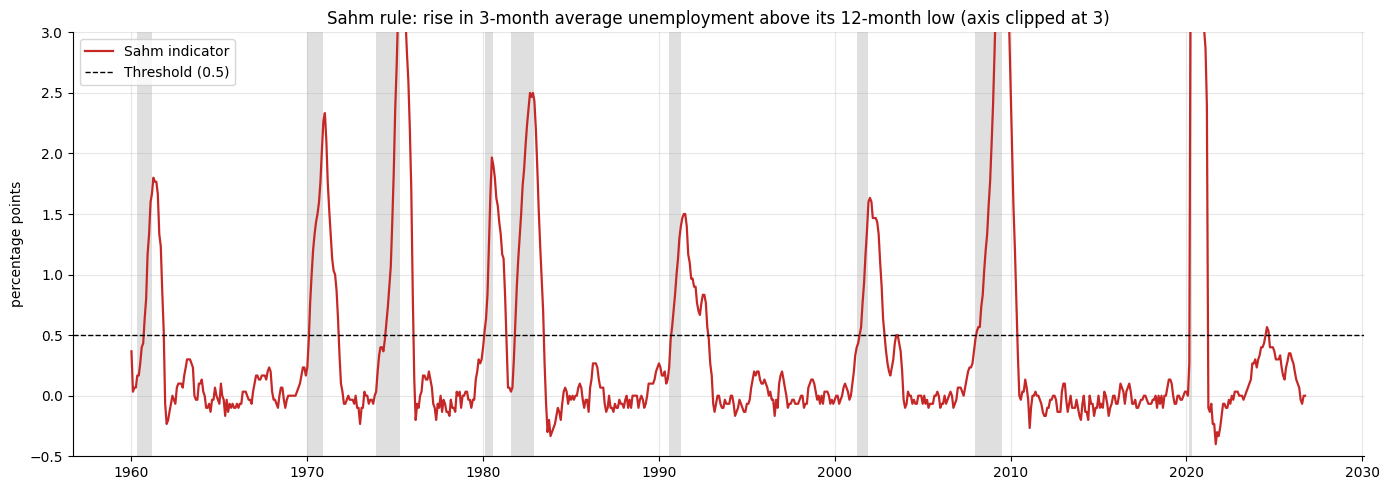

Sahm triggers not associated with an NBER recession: ['Jul 2003', 'Jul 2024']


In [11]:
fig, ax = plt.subplots(figsize=(14, 5))
s = df["sahm"].loc["1960-01-01":]
shade_recessions(ax, df["USREC"], "1960-01-01")
ax.plot(s.index, s, color="#c62828", lw=1.6, label="Sahm indicator")
ax.axhline(SAHM_THRESHOLD, color="black", ls="--", lw=1, label=f"Threshold ({SAHM_THRESHOLD})")
ax.set_ylim(-0.5, 3)
ax.set_ylabel("percentage points")
ax.set_title("Sahm rule: rise in 3-month average unemployment above its 12-month low (axis clipped at 3)")
ax.legend(loc="upper left")
fig.tight_layout()
save(fig, "06_sahm_rule.png")
plt.show()

false_sahm = []
trig_months = df.index[(df["sahm"] >= SAHM_THRESHOLD) & (df["sahm"].shift(1) < SAHM_THRESHOLD)]
for t in trig_months[trig_months >= pd.Timestamp("1960-01-01")]:
    near = [st for st in all_starts if -3 <= months_between(st, t) <= 18]
    if not near and months_between(t, LAST_REC_KNOWN) >= 12:
        false_sahm.append(f"{t:%b %Y}")
print("Sahm triggers not associated with an NBER recession:", false_sahm if false_sahm else "none")

## Step 7: Today's reading

In [12]:
latest = df.loc[LAST]
current = {
    "Date": f"{LAST:%B %Y}",
    "10y-3m spread (pp)": latest["spread"],
    "10y-2y spread (pp)": latest["spread_2y"],
    "BAA credit spread (pp)": latest["credit_spread"],
    "Probability, spread only (%)": 100 * oos["Spread only"].loc[LAST],
    "Probability, spread + credit (%)": 100 * oos["Spread + credit"].loc[LAST],
    "Sahm indicator (pp)": df["sahm"].dropna().iloc[-1],
    "Sahm rule triggered": "yes" if df["sahm"].dropna().iloc[-1] >= SAHM_THRESHOLD else "no",
}
current = pd.Series(current, name="value").to_frame()
current.to_csv(f"{TAB}/current_reading.csv")
display(current)

recent = pd.DataFrame({name: 100 * oos[name] for name in MODELS}).loc[LAST - pd.DateOffset(months=11):LAST]
recent.index = recent.index.strftime("%b %Y")
print("\nProbability of recession 12 months ahead, last 12 months (%)")
display(recent)

,value
Date,October 2026
10y-3m spread (pp),1.08
10y-2y spread (pp),0.39
BAA credit spread (pp),1.46
"Probability, spread only (%)",10.06
"Probability, spread + credit (%)",10.01
Sahm indicator (pp),0.00
Sahm rule triggered,no



Probability of recession 12 months ahead, last 12 months (%)


,Spread only,Spread + credit
observation_date,,
Nov 2025,20.41,20.42
Dec 2025,16.73,16.73
Jan 2026,15.45,15.43
Feb 2026,16.94,16.92
Mar 2026,15.37,15.37
Apr 2026,14.42,14.40
May 2026,12.32,12.29
Jun 2026,13.11,13.07
Jul 2026,12.38,12.34


## Automatic export for GitHub

This cell writes a complete `README.md` with today's numbers and interpretation, adds `requirements.txt` and `.gitignore`, and zips everything with the charts and tables. In Colab the zip is downloaded automatically.

**What to upload to GitHub:** unzip the file, select **all** its contents (including the `figures` and `tables` folders) and drag them into *Add file → Upload files*. Then upload this notebook too (*File → Download → Download .ipynb*), saved after running it.

In [13]:
TODAY = date.today().strftime("%d %B %Y")


def fmt(v):
    if isinstance(v, (int, np.integer)):
        return str(v)
    if isinstance(v, (float, np.floating)):
        return "–" if np.isnan(v) else f"{v:.2f}"
    return str(v)


def md_table(df_, index_name=""):
    cols = [str(c) for c in df_.columns]
    lines = [f"| {index_name} | " + " | ".join(cols) + " |", "|---|" + "---|" * len(cols)]
    for idx, row in df_.iterrows():
        lines.append(f"| {idx} | " + " | ".join(fmt(v) for v in row) + " |")
    return "\n".join(lines)


pt = probit_table.astype(float)
ot = oos_table.astype(float)
rt = recession_table.copy()
n_rec = len(rt)
n_inv_before = int((rt["first inversion"] != "no inversion").sum())
leads = rt["lead (months)"].astype(float).dropna()
lags = rt["Sahm lag (months)"].astype(float).dropna()
false_alarms = [k for k, v in episode_table["outcome"].items() if "false alarm" in v]
too_early = [k for k, v in episode_table["outcome"].items() if "too early" in v]
p_now = current.loc["Probability, spread only (%)", "value"]
p_now_c = current.loc["Probability, spread + credit (%)", "value"]
spread_now = current.loc["10y-3m spread (pp)", "value"]
sahm_now = current.loc["Sahm indicator (pp)", "value"]

summary = (
    f"Since 1960 the 10-year minus 3-month Treasury spread inverted before **{n_inv_before} of the {n_rec}** US recessions, "
    f"with a median lead of **{leads.median():.0f} months**. A probit model re-estimated in real time since 1978 reaches an "
    f"out-of-sample AUC of **{ot.loc['Spread only', 'AUC out-of-sample']:.2f}**. The Sahm rule confirmed recessions a median of "
    f"{lags.median():.0f} months after they started. In {current.loc['Date', 'value']} the spread is {spread_now:+.2f} pp and the "
    f"model's probability of a recession within 12 months is **{p_now:.0f}%**."
)

coef_text = (
    f"The spread coefficient is {pt.loc['Spread only', 'spread']:.2f} (s.e. {pt.loc['Spread only', 'spread s.e.']:.2f}): "
    f"a flatter curve significantly raises the probability of recession. The model assigns a 30% probability when the spread "
    f"is {thresholds[0.3]:+.2f} pp and 50% when it is {thresholds[0.5]:+.2f} pp. Adding the credit spread "
    f"{'improves' if pt.loc['Spread + credit', 'pseudo R²'] > pt.loc['Spread only', 'pseudo R²'] + 0.01 else 'barely changes'} "
    f"the in-sample fit (pseudo-R² {pt.loc['Spread only', 'pseudo R²']:.2f} → {pt.loc['Spread + credit', 'pseudo R²']:.2f})."
)

oos_text = (
    f"Out of sample the spread-only model reaches an AUC of {ot.loc['Spread only', 'AUC out-of-sample']:.2f}, against "
    f"{ot.loc['Spread only', 'AUC in-sample, same months']:.2f} in-sample on the same months: "
    + ("most of the predictive power survives in real time. " if ot.loc['Spread only', 'AUC out-of-sample'] > 0.75
       else "part of the in-sample fit does not survive in real time. ")
    + f"The model with the credit spread reaches {ot.loc['Spread + credit', 'AUC out-of-sample']:.2f}. "
    f"On average the real-time probability was {ot.loc['Spread only', 'avg probability, recession months (%)']:.0f}% ahead of "
    f"recession months and {ot.loc['Spread only', 'avg probability, other months (%)']:.0f}% otherwise."
)

fa_text = ("Inversions not followed by a recession within 24 months: " + ", ".join(false_alarms) + ". "
           if false_alarms else "No inversion in the sample was a false alarm. ")
if too_early:
    fa_text += "Too early to judge: " + ", ".join(too_early) + "."

now_text = (
    f"In {current.loc['Date', 'value']} the 10y-3m spread is {spread_now:+.2f} pp, the 10y-2y spread "
    f"{current.loc['10y-2y spread (pp)', 'value']:+.2f} pp and the BAA credit spread {current.loc['BAA credit spread (pp)', 'value']:.2f} pp. "
    f"The real-time probability of a recession within 12 months is **{p_now:.0f}%** (spread only) and **{p_now_c:.0f}%** "
    f"(spread + credit). The Sahm indicator is {sahm_now:.2f} pp, "
    + ("**above** the 0.5 threshold: the labour market signals that a recession may already be under way."
       if sahm_now >= SAHM_THRESHOLD else "below the 0.5 threshold: the labour market does not signal a recession.")
)

badge = f"https://colab.research.google.com/github/{GITHUB_USERNAME}/{REPO_NAME}/blob/main/{NOTEBOOK_NAME}"
probit_md = pt[["months", "spread", "spread s.e.", "credit_spread", "credit_spread s.e.", "pseudo R²", "AUC (in-sample)"]].copy()
probit_md["months"] = probit_md["months"].astype(int)
current_md = current.copy()
current_md["value"] = [fmt(v) for v in current_md["value"]]

readme = f"""# Yield Curve Recession Model

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)]({badge})

**Author:** {AUTHOR}
**Last updated:** {TODAY} (numbers and charts are generated automatically by the notebook)

## Summary

{summary}

## Research question

How well does the slope of the US Treasury yield curve predict recessions twelve months ahead? Does the signal survive a real-time test, how often does it give false alarms, and how does it compare with a labour-market indicator (the Sahm rule)?

## Why the yield curve predicts recessions

- **Expectations:** long-term yields reflect expected future short rates. When markets expect the central bank to cut rates in a coming downturn, long yields fall below short ones.
- **Monetary policy:** an inversion usually means short rates have been raised to a restrictive level. Banks borrow short and lend long, so a flat or inverted curve squeezes lending margins and credit supply.

## Data

All monthly, from FRED: 10-year (GS10), 2-year (GS2) and 3-month (TB3MS) Treasury yields, Moody's BAA corporate yield, the unemployment rate and the NBER recession indicator (USREC). Estimation from 1959.

## Methodology

1. **Probit model** of the probability of being in recession 12 months ahead, $P(\\text{{rec}}_{{t+12}}) = \\Phi(\\alpha + \\beta\\,\\text{{spread}}_t)$, as in Estrella and Mishkin (1998) and the New York Fed. A second version adds the BAA-10y credit spread. HAC standard errors.
2. **Out-of-sample test:** from 1978 the model is re-estimated every month using only outcomes known at the time, and evaluated with the AUC (area under the ROC curve).
3. **Event analysis:** lead time of each inversion, maximum real-time probability before each recession, and false alarms.
4. **Sahm rule:** 3-month average unemployment rising 0.5 pp above its 12-month low, as a confirming signal.

## Results

### 1. The yield curve and recessions

![Spreads](figures/01_yield_curve_spreads.png)

### 2. Probit model

![Probability vs spread](figures/02_probability_vs_spread.png)

{md_table(probit_md, "Model")}

{coef_text}

### 3. Real-time performance

![Recession probability](figures/03_recession_probability.png)

![ROC curves](figures/04_roc_curves.png)

{md_table(ot, "Model")}

{oos_text}

### 4. Recession by recession

![Lead times](figures/05_lead_times.png)

{md_table(recession_table, "Recession start")}

### 5. Inversion episodes and false alarms

{md_table(episode_table, "Inversion episode")}

{fa_text}

### 6. The Sahm rule

![Sahm rule](figures/06_sahm_rule.png)

### 7. Today's reading

{md_table(current_md, "")}

{now_text}

## Limitations

- **Few events.** Only about eight recessions since 1960, so every estimate rests on a handful of episodes.
- **NBER dates are announced with a lag** of 6-18 months, so a real-time forecaster would have known recession outcomes later than assumed here; recent months may also belong to a recession not yet dated.
- **Structural change.** Quantitative easing and a lower term premium may have flattened the curve for reasons unrelated to recession risk, making inversions less informative.
- **Revised data.** The unemployment rate used for the Sahm rule is revised; the real-time version can differ.
- **Bill yields** are on a discount basis while the New York Fed converts them to a bond-equivalent basis; differences are small.

## Possible extensions

- Add the near-term forward spread (Engstrom and Sharpe, 2019) and the excess bond premium (Gilchrist and Zakrajšek, 2012)
- Euro-area version with Bund yields
- Combine curve and Sahm rule in a single model

## How to run

**Google Colab (recommended):** click the "Open in Colab" badge above, then *Runtime → Run all*.

**Locally:**
```bash
git clone https://github.com/{GITHUB_USERNAME}/{REPO_NAME}.git
cd {REPO_NAME}
pip install -r requirements.txt
jupyter notebook {NOTEBOOK_NAME}
```

## References

- Estrella, A. and Mishkin, F. S. (1998). Predicting U.S. recessions: financial variables as leading indicators. *Review of Economics and Statistics*, 80(1), 45-61.
- Estrella, A. and Hardouvelis, G. A. (1991). The term structure as a predictor of real economic activity. *Journal of Finance*, 46(2), 555-576.
- Sahm, C. (2019). Direct stimulus payments to individuals. In *Recession Ready*, Brookings Institution / Hamilton Project.

---

*Research and educational project. Not investment advice.*
"""

with open(f"{OUT}/README.md", "w", encoding="utf-8") as f:
    f.write(readme)
with open(f"{OUT}/requirements.txt", "w") as f:
    f.write("pandas>=2.2\nnumpy\nmatplotlib\nscipy\nstatsmodels\nscikit-learn\njupyter\n")
with open(f"{OUT}/.gitignore", "w") as f:
    f.write("*.zip\n__pycache__/\n.ipynb_checkpoints/\n.venv/\n.DS_Store\n")

zip_path = shutil.make_archive(REPO_NAME, "zip", OUT)
print(f"Created {zip_path} with:")
for root, _, files in os.walk(OUT):
    for name in sorted(files):
        print("  ", os.path.relpath(os.path.join(root, name), OUT))
try:
    from google.colab import files
    files.download(zip_path)
except ImportError:
    print("Not running in Colab: the zip file is in the current folder.")

Created /content/yield-curve-recession-model.zip with:
   .gitignore
   README.md
   requirements.txt
   tables/current_reading.csv
   tables/inversion_episodes.csv
   tables/out_of_sample_evaluation.csv
   tables/probit_estimates.csv
   tables/recessions_lead_times.csv
   figures/01_yield_curve_spreads.png
   figures/02_probability_vs_spread.png
   figures/03_recession_probability.png
   figures/04_roc_curves.png
   figures/05_lead_times.png
   figures/06_sahm_rule.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [14]:
from IPython.display import Markdown
Markdown(readme)

# Yield Curve Recession Model

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/gabsmm18/yield-curve-recession-model/blob/main/yield_curve_recession_model.ipynb)

**Author:** Mattia Mariani
**Last updated:** 19 November 2026 (numbers and charts are generated automatically by the notebook)

## Summary

Since 1960 the 10-year minus 3-month Treasury spread inverted before **7 of the 9** US recessions, with a median lead of **12 months**. A probit model re-estimated in real time since 1978 reaches an out-of-sample AUC of **0.80**. The Sahm rule confirmed recessions a median of 2 months after they started. In October 2026 the spread is +1.08 pp and the model's probability of a recession within 12 months is **10%**.

## Research question

How well does the slope of the US Treasury yield curve predict recessions twelve months ahead? Does the signal survive a real-time test, how often does it give false alarms, and how does it compare with a labour-market indicator (the Sahm rule)?

## Why the yield curve predicts recessions

- **Expectations:** long-term yields reflect expected future short rates. When markets expect the central bank to cut rates in a coming downturn, long yields fall below short ones.
- **Monetary policy:** an inversion usually means short rates have been raised to a restrictive level. Banks borrow short and lend long, so a flat or inverted curve squeezes lending margins and credit supply.

## Data

All monthly, from FRED: 10-year (GS10), 2-year (GS2) and 3-month (TB3MS) Treasury yields, Moody's BAA corporate yield, the unemployment rate and the NBER recession indicator (USREC). Estimation from 1959.

## Methodology

1. **Probit model** of the probability of being in recession 12 months ahead, $P(\text{rec}_{t+12}) = \Phi(\alpha + \beta\,\text{spread}_t)$, as in Estrella and Mishkin (1998) and the New York Fed. A second version adds the BAA-10y credit spread. HAC standard errors.
2. **Out-of-sample test:** from 1978 the model is re-estimated every month using only outcomes known at the time, and evaluated with the AUC (area under the ROC curve).
3. **Event analysis:** lead time of each inversion, maximum real-time probability before each recession, and false alarms.
4. **Sahm rule:** 3-month average unemployment rising 0.5 pp above its 12-month low, as a confirming signal.

## Results

### 1. The yield curve and recessions

![Spreads](figures/01_yield_curve_spreads.png)

### 2. Probit model

![Probability vs spread](figures/02_probability_vs_spread.png)

| Model | months | spread | spread s.e. | credit_spread | credit_spread s.e. | pseudo R² | AUC (in-sample) |
|---|---|---|---|---|---|---|---|
| Spread only | 802.00 | -0.56 | 0.12 | – | – | 0.19 | 0.82 |
| Spread + credit | 802.00 | -0.56 | 0.13 | 0.01 | 0.24 | 0.19 | 0.82 |

The spread coefficient is -0.56 (s.e. 0.12): a flatter curve significantly raises the probability of recession. The model assigns a 30% probability when the spread is -0.27 pp and 50% when it is -1.20 pp. Adding the credit spread barely changes the in-sample fit (pseudo-R² 0.19 → 0.19).

### 3. Real-time performance

![Recession probability](figures/03_recession_probability.png)

![ROC curves](figures/04_roc_curves.png)

| Model | months | AUC out-of-sample | AUC in-sample, same months | avg probability, recession months (%) | avg probability, other months (%) |
|---|---|---|---|---|---|
| Spread only | 574.00 | 0.80 | 0.82 | 31.13 | 11.63 |
| Spread + credit | 574.00 | 0.78 | 0.82 | 29.94 | 12.40 |

Out of sample the spread-only model reaches an AUC of 0.80, against 0.82 in-sample on the same months: most of the predictive power survives in real time. The model with the credit spread reaches 0.78. On average the real-time probability was 31% ahead of recession months and 12% otherwise.

### 4. Recession by recession

![Lead times](figures/05_lead_times.png)

| Recession start | first inversion | lead (months) | max real-time probability (%) | Sahm rule triggered | Sahm lag (months) |
|---|---|---|---|---|---|
| May 1960 | no inversion | – | – | Oct 1960 | 5 |
| Jan 1970 | Jan 1969 | 12 | – | Mar 1970 | 2 |
| Dec 1973 | Jun 1973 | 6 | – | Jul 1974 | 7 |
| Feb 1980 | Dec 1978 | 14 | 87.65 | Feb 1980 | 0 |
| Aug 1981 | Aug 1979 | 24 | 95.16 | Nov 1981 | 3 |
| Aug 1990 | no inversion | – | 28.60 | Oct 1990 | 2 |
| Apr 2001 | Aug 2000 | 8 | 46.86 | Jun 2001 | 2 |
| Jan 2008 | Aug 2006 | 17 | 44.26 | Feb 2008 | 1 |
| Mar 2020 | Jun 2019 | 9 | 43.41 | Apr 2020 | 1 |

### 5. Inversion episodes and false alarms

| Inversion episode | inverted months | deepest inversion (pp) | outcome |
|---|---|---|---|
| Sep 1966 - Jan 1967 | 5 | -0.34 | no recession within 24 months (false alarm) |
| Jul 1969 - Jan 1970 | 5 | -0.29 | recession (Jan 1970, 6 months later) |
| Jun 1973 - Sep 1974 | 15 | -1.27 | recession (Dec 1973, 6 months later) |
| Dec 1978 - Apr 1980 | 17 | -2.45 | recession (Feb 1980, 14 months later) |
| Nov 1980 - Aug 1981 | 10 | -2.65 | recession (Aug 1981, 9 months later) |
| Aug 2000 - Dec 2000 | 5 | -0.53 | recession (Apr 2001, 8 months later) |
| Aug 2006 - Apr 2007 | 9 | -0.38 | recession (Jan 2008, 17 months later) |
| Jun 2019 - Sep 2019 | 4 | -0.32 | recession (Mar 2020, 9 months later) |
| Nov 2022 - Nov 2024 | 25 | -1.57 | no recession within 24 months (false alarm) |

Inversions not followed by a recession within 24 months: Sep 1966 - Jan 1967, Nov 2022 - Nov 2024. 

### 6. The Sahm rule

![Sahm rule](figures/06_sahm_rule.png)

### 7. Today's reading

|  | value |
|---|---|
| Date | October 2026 |
| 10y-3m spread (pp) | 1.08 |
| 10y-2y spread (pp) | 0.39 |
| BAA credit spread (pp) | 1.46 |
| Probability, spread only (%) | 10.06 |
| Probability, spread + credit (%) | 10.01 |
| Sahm indicator (pp) | 0.00 |
| Sahm rule triggered | no |

In October 2026 the 10y-3m spread is +1.08 pp, the 10y-2y spread +0.39 pp and the BAA credit spread 1.46 pp. The real-time probability of a recession within 12 months is **10%** (spread only) and **10%** (spread + credit). The Sahm indicator is 0.00 pp, below the 0.5 threshold: the labour market does not signal a recession.

## Limitations

- **Few events.** Only about eight recessions since 1960, so every estimate rests on a handful of episodes.
- **NBER dates are announced with a lag** of 6-18 months, so a real-time forecaster would have known recession outcomes later than assumed here; recent months may also belong to a recession not yet dated.
- **Structural change.** Quantitative easing and a lower term premium may have flattened the curve for reasons unrelated to recession risk, making inversions less informative.
- **Revised data.** The unemployment rate used for the Sahm rule is revised; the real-time version can differ.
- **Bill yields** are on a discount basis while the New York Fed converts them to a bond-equivalent basis; differences are small.

## Possible extensions

- Add the near-term forward spread (Engstrom and Sharpe, 2019) and the excess bond premium (Gilchrist and Zakrajšek, 2012)
- Euro-area version with Bund yields
- Combine curve and Sahm rule in a single model

## How to run

**Google Colab (recommended):** click the "Open in Colab" badge above, then *Runtime → Run all*.

**Locally:**
```bash
git clone https://github.com/gabsmm18/yield-curve-recession-model.git
cd yield-curve-recession-model
pip install -r requirements.txt
jupyter notebook yield_curve_recession_model.ipynb
```

## References

- Estrella, A. and Mishkin, F. S. (1998). Predicting U.S. recessions: financial variables as leading indicators. *Review of Economics and Statistics*, 80(1), 45-61.
- Estrella, A. and Hardouvelis, G. A. (1991). The term structure as a predictor of real economic activity. *Journal of Finance*, 46(2), 555-576.
- Sahm, C. (2019). Direct stimulus payments to individuals. In *Recession Ready*, Brookings Institution / Hamilton Project.

---

*Research and educational project. Not investment advice.*
